# Evaluating the Skincare Recommender

Does the recommender actually find similar products? This notebook tests it three ways.

1. **Size variants.** The same product sold in two sizes has the same formula. A good model should rank the other size first.
2. **Published dupes.** Pairs that beauty editors and dupe sites link together. Where does the model rank the known alternative?
3. **Behaviour across the catalogue.** Coverage, brand variety and how much the dupe mode saves.

Each test compares the **current model** with the **original model** and a **random baseline**.

| Model | Ingredient tokens | Ingredient families | Price signal | Rating signal | Size variants |
|---|---|---|---|---|---|
| Original | Single words ("sodium hyaluronate" becomes "sodium" + "hyaluronate") | No | Similar price | Similar rating | Can be recommended |
| Current | Whole ingredient names | Yes | Similar price, or bigger saving in dupe mode | Higher rating | Never recommended |

**Ingredient families** group related ingredients. Sodium hyaluronate and hyaluronic acid both count as hyaluronic acid, for example. Matching ingredients still score highest. A shared family adds partial credit. Results are also shown for the current model with families turned off, so the effect of each change is visible.

In [1]:
import sys
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import recommender as r  # noqa: E402

df = r.load_data(ROOT / 'data' / 'skincare_products.csv')
df['product_id'] = df['product_id'].astype(str)
df['base'] = df['product_name'].map(r.base_name)
TYPES = {t: g.reset_index(drop=True) for t, g in df.groupby('product_type')}
print(f'{len(df):,} available products across {len(TYPES)} product types')

2026-11-19 01:06:03.702 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 01:06:03.705 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 01:06:03.705 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


1,032 available products across 14 product types


## The original model

The original scoring code is reproduced here so both models run on the same data.

In [2]:
def legacy_ingredient_similarity(g, i):
    def weighted_str(ingredients):
        parts = []
        for rank, ingr in enumerate(ingredients, start=1):
            parts.extend([str(ingr).strip()] * max(1, 6 - rank))
        return ' '.join(parts)
    vectors = TfidfVectorizer().fit_transform(g['ingredients'].apply(weighted_str))
    return cosine_similarity(vectors[i], vectors).flatten()


def legacy_scores(g, i):
    sim = legacy_ingredient_similarity(g, i)
    prices = pd.to_numeric(g['display_price'], errors='coerce')
    sel, spread = prices.iloc[i], prices.max() - prices.min()
    price = (1 - (prices - sel).abs() / spread).clip(0, 1).fillna(0.5) if pd.notnull(sel) and spread > 0 else pd.Series(0.5, index=g.index)
    ratings = pd.to_numeric(g['product_rating'], errors='coerce')
    sel_r = ratings.iloc[i]
    rating = (1 - (ratings - sel_r).abs() / 5).clip(0, 1).fillna(0.5) if pd.notnull(sel_r) else pd.Series(0.5, index=g.index)
    return 0.75 * sim + 0.15 * price.values + 0.10 * rating.values


def legacy_recommend(g, i, top_n=5, threshold=0.1):
    sim, scores = legacy_ingredient_similarity(g, i), legacy_scores(g, i)
    picks = [j for j in scores.argsort()[::-1] if j != i and sim[j] >= threshold][:top_n]
    return g.iloc[picks]


def current_scores(g, i, cheaper_only=False, use_families=True):
    sim = r.ingredient_similarity(g, i, use_families=use_families)
    prices = pd.to_numeric(g['display_price'], errors='coerce')
    price = r.price_scores(prices, prices.iloc[i], cheaper_only)
    rating = r.rating_scores(pd.to_numeric(g['product_rating'], errors='coerce'))
    w = r.WEIGHTS
    return w['ingredients'] * sim + w['price'] * price.values + w['rating'] * rating.values

## Test 1: Size variants

Some products are listed in more than one size. Each size should have the same ingredients. So for every product with a size variant we ask one question. Is the variant ranked first by ingredient match?

We report three measures.

- **Hit@1** is the share of products where a variant is ranked first.
- **Hit@5** is the share where a variant is in the top five.
- **MRR** (mean reciprocal rank) averages 1 ÷ the variant's rank. 1.0 is perfect.

The random baseline is the expected score from shuffling the candidates.

In [3]:
groups = df.groupby(['product_type', 'base'])
variant_groups = [g for _, g in groups if len(g) > 1]
identical = sum(len({tuple(x) for x in g['ingredients']}) == 1 for g in variant_groups)
print(f'{len(variant_groups)} products come in more than one size ({sum(len(g) for g in variant_groups)} listings)')
print(f'{identical} of {len(variant_groups)} groups have identical ingredient lists across sizes')

47 products come in more than one size (101 listings)
35 of 47 groups have identical ingredient lists across sizes


In [4]:
def variant_ranks(similarity_fn):
    ranks, rand_hit1, rand_hit5 = [], [], []
    for g in TYPES.values():
        for i in range(len(g)):
            relevant = (g['base'] == g['base'][i]) & (g.index != i)
            if not relevant.any():
                continue
            candidates = g.index != i
            sims = pd.Series(similarity_fn(g, i))[candidates].sort_values(ascending=False, kind='stable')
            ranks.append(next(pos for pos, j in enumerate(sims.index, 1) if relevant[j]))
            n, m = candidates.sum(), relevant.sum()
            rand_hit1.append(m / n)
            rand_hit5.append(1 - comb(n - m, 5) / comb(n, 5))
    return np.array(ranks), np.mean(rand_hit1), np.mean(rand_hit5)


cur_ranks, rand1, rand5 = variant_ranks(r.ingredient_similarity)
old_ranks, _, _ = variant_ranks(legacy_ingredient_similarity)
nofam_ranks, _, _ = variant_ranks(lambda g, i: r.ingredient_similarity(g, i, use_families=False))

def summarise(ranks):
    return {'Hit@1': (ranks == 1).mean(), 'Hit@5': (ranks <= 5).mean(), 'MRR': (1 / ranks).mean()}

test1 = pd.DataFrame({
    'Random': {'Hit@1': rand1, 'Hit@5': rand5, 'MRR': np.nan},
    'Original': summarise(old_ranks),
    'Current without families': summarise(nofam_ranks),
    'Current': summarise(cur_ranks),
}).T
test1.round(3)

,Hit@1,Hit@5,MRR
Random,0.018,0.087,NaN
Original,0.950,1.000,0.969
Current without families,0.941,0.980,0.960
Current,0.941,0.980,0.960


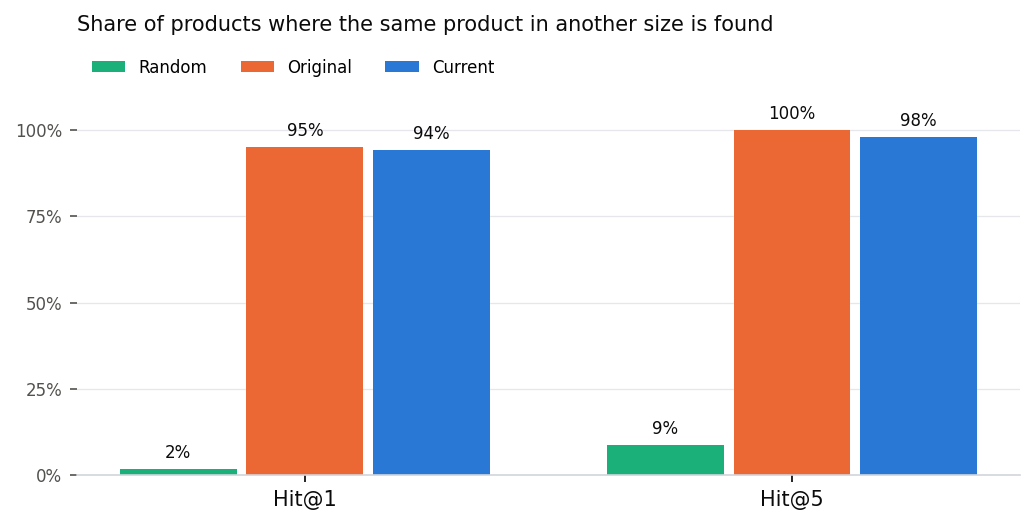

In [5]:
COLORS = {'Random': '#1baf7a', 'Original': '#eb6834', 'Current': '#2a78d6'}
INK, MUTED = '#0b0b0b', '#52514e'

fig, ax = plt.subplots(figsize=(7, 3.6), dpi=150)
metrics, width = ['Hit@1', 'Hit@5'], 0.24
x = np.arange(len(metrics))
for k, model in enumerate(['Random', 'Original', 'Current']):
    vals = test1.loc[model, metrics].values
    bars = ax.bar(x + (k - 1) * (width + 0.02), vals, width, color=COLORS[model], label=model)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f'{v:.0%}', ha='center', va='bottom', fontsize=8, color=INK)
ax.set_xticks(x, metrics, color=INK)
ax.set_ylim(0, 1.25)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.tick_params(axis='y', colors=MUTED, labelsize=8)
ax.grid(axis='y', color='#e5e7eb', linewidth=0.6)
ax.set_axisbelow(True)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.spines['bottom'].set_color('#d1d5db')
ax.set_title('Share of products where the same product in another size is found', fontsize=10, color=INK, loc='left')
ax.legend(frameon=False, fontsize=8, ncol=3, loc='upper left', bbox_to_anchor=(0, 1.0))
fig.tight_layout()
fig.savefig(ROOT / 'docs' / 'evaluation_size_variants.png', facecolor='white')
plt.show()

**Reading the result.** Both models find the matching size almost every time. Random guessing would get it right about 2% of the time. This confirms the ingredient matching works on clear cases.

This is a sanity check rather than a hard test. Most variant groups have identical ingredient lists so any sensible model should pass. The two models are close here. The original model edges ahead on variants whose scraped lists differ slightly, because single words still overlap when an ingredient name is spelled differently.

**Change made from this test.** Size variants used to take up recommendation slots. The current app now hides the selected product's other sizes and shows each product once.

## Test 2: Published dupes

These pairs come from beauty editors, dupe finder sites and shopper comparisons. Only pairs where both products are in this catalogue and share a product type can be tested. The app only compares products of the same type.

| Source product | Alternative | Link between them |
|---|---|---|
| Elemis Pro-Collagen Cleansing Balm | Clinique Take The Day Off Cleansing Balm | Editor dupe pick ([Cosmetify](https://www.cosmetify.com/blog/elemis-cleansing-balm-dupes)) |
| Elemis Pro-Collagen Cleansing Balm | Emma Hardie Moringa Cleansing Balm | Closest formula on a dupe finder ([What's in my Jar](https://whatsinmyjar.com/product/elemis-pro-collagen-cleansing-balm/dupes)) |
| Vichy Minéral 89 | The Ordinary Hyaluronic Acid 2% + B5 | Commonly compared ([GetSkinScore](https://getskinscore-site.pages.dev/product/vichy-mineral-89)) |
| First Aid Beauty Ultra Repair Cream | CeraVe Moisturising Cream | Commonly compared ([GetSkinScore](https://getskinscore-site.pages.dev/product/first-aid-beauty-ultra-repair-cream)) |
| Estée Lauder Advanced Night Repair | Lancôme Advanced Génifique | Commonly compared ([Sephora Community](https://community.sephora.com/t5/Age-Defiers/Est%C3%A9e-Lauder-vs-Lanc%C3%B4me/m-p/6483750)) |

For each pair we find the alternative's rank among all products of that type. Each product is counted once whatever its size. A rank of 5 or better means it appears in the app.

In [6]:
# Product IDs, so the test keeps working when the pipeline renames products
PAIRS = [
    ('10757840', '12076052'),  # Elemis Pro-Collagen Cleansing Balm -> Clinique Take The Day Off Balm
    ('10757840', '11255285'),  # Elemis Pro-Collagen Cleansing Balm -> Emma Hardie Moringa Balm
    ('11499284', '12243647'),  # Vichy Minéral 89 -> The Ordinary Hyaluronic Acid 2% + B5
    ('11054496', '11798693'),  # First Aid Beauty Ultra Repair Cream -> CeraVe Moisturising Cream
    ('11141115', '12218773'),  # Estée Lauder Advanced Night Repair -> Lancôme Advanced Génifique
]


def rank_of(g, i, j, scores):
    s = pd.Series(scores)[g['base'] != g['base'][i]]
    ranked = (pd.DataFrame({'score': s, 'base': g['base'][s.index]})
              .sort_values('score', ascending=False)
              .drop_duplicates('base'))
    return list(ranked['base']).index(g['base'][j]) + 1, len(ranked)


rows = []
for src, tgt in PAIRS:
    ptype = df.loc[df['product_id'] == src, 'product_type'].iloc[0]
    g = TYPES[ptype]
    i = g.index[g['product_id'] == src][0]
    j = g.index[g['product_id'] == tgt][0]
    cur, n = rank_of(g, i, j, current_scores(g, i))
    nofam, _ = rank_of(g, i, j, current_scores(g, i, use_families=False))
    old, _ = rank_of(g, i, j, legacy_scores(g, i))
    short = lambda name: ' '.join(name.split(' ')[:4])
    rows.append({
        'Source': short(g['product_name'][i]),
        'Alternative': short(g['product_name'][j]),
        'Type': ptype,
        'Candidates': n,
        'Original rank': old,
        'Without families': nofam,
        'Current rank': cur,
        'Ingredient match': r.ingredient_similarity(g, i)[j],
        'Price saving': 1 - g['display_price'][j] / g['display_price'][i],
    })

test2 = pd.DataFrame(rows)
test2['Random rank (expected)'] = (test2['Candidates'] + 1) / 2
test2.assign(**{
    'Ingredient match': test2['Ingredient match'].map('{:.0%}'.format),
    'Price saving': test2['Price saving'].map('{:.0%}'.format),
    'Random rank (expected)': test2['Random rank (expected)'].round(0).astype(int),
})

,Source,Alternative,Type,Candidates,Original rank,Without families,Current rank,Ingredient match,Price saving,Random rank (expected)
0,Elemis Pro-Collagen Cleansing Balm,Clinique Take the Day,Cleanser,98,11,9,9,12%,39%,50
1,Elemis Pro-Collagen Cleansing Balm,Emma Hardie Moringa Cleansing,Cleanser,98,1,1,1,58%,7%,50
2,VICHY Minéral 89 Hyaluronic,The Ordinary Hyaluronic Acid,Serum,98,16,24,17,9%,37%,50
3,First Aid Beauty Ultra,CeraVe Moisturising Cream 177ml,Moisturiser,98,12,7,5,17%,-21%,50
4,Estée Lauder Advanced Night,Lancôme Advanced Génifique Youth,Serum,98,2,3,3,36%,-30%,50


In [7]:
for col in ['Original rank', 'Without families', 'Current rank']:
    print(f"{col:18} median rank {test2[col].median():>4.0f}   in the top 5: {(test2[col] <= 5).sum()} of {len(test2)}")
print(f"{'Random':18} median rank {test2['Random rank (expected)'].median():>4.0f}")
print(f"Pairs in the top 10%. Current: {(test2['Current rank'] <= test2['Candidates'] * 0.1).sum()} of {len(test2)}")

Original rank      median rank   11   in the top 5: 2 of 5
Without families   median rank    7   in the top 5: 2 of 5
Current rank       median rank    5   in the top 5: 3 of 5
Random             median rank   50
Pairs in the top 10%. Current: 4 of 5


**Reading the result.** Every alternative ranks well above chance. The expected random rank is about 50 out of 98. The median rank is 5 with the current model, 7 without families and 11 with the original. Three of the five pairs reach the top five and the Emma Hardie balm is ranked first. Four of the five are in the top 10% of their category and all five are in the top quarter.

The pairs that rank lower share fewer exact ingredients. Vichy Minéral 89 and The Ordinary both rely on sodium hyaluronate. Their other ingredients differ. Dupe sites close this gap with extra signals such as product function and key actives. Ingredient families close part of it here.

Families lift the pairs that do the same job with different ingredients. Vichy and The Ordinary rise from 24th to 17th. CeraVe rises from 7th to 5th. Size-variant matching does not change. Five pairs is a small sample, so this is a good sign rather than proof. Families were added because the chemistry supports them, not to fit these five pairs. For the same reason I did not tune any weights on these pairs.

## Test 3: Behaviour across the catalogue

These checks run every available product through both models.

In [8]:
records = []
for ptype, g in TYPES.items():
    same_brand_base = []
    for i in range(len(g)):
        new = r.recommend(g, i)
        old = legacy_recommend(g, i)
        cheap = r.recommend(g, i, cheaper_only=True)
        brand = g['brand'][i]
        records.append({
            'type': ptype,
            'n_new': len(new),
            'n_old': len(old),
            'variants_old': (old['product_name'].map(r.base_name) == g['base'][i]).sum(),
            'variants_new': (new['product_name'].map(r.base_name) == g['base'][i]).sum(),
            'same_brand_old': (old['brand'] == brand).sum() if pd.notnull(brand) else np.nan,
            'same_brand_new': (new['brand'] == brand).sum() if pd.notnull(brand) else np.nan,
            'brand_base_rate': ((g['brand'] == brand).sum() - 1) / (len(g) - 1) if pd.notnull(brand) else np.nan,
            'n_cheaper': len(cheap),
            'median_saving': (1 - cheap['display_price'] / g['display_price'][i]).median() if len(cheap) else np.nan,
        })
behaviour = pd.DataFrame(records)

summary = pd.DataFrame({
    'Original': {
        'Products with 5 results': (behaviour['n_old'] == 5).mean(),
        'Products with no results': (behaviour['n_old'] == 0).mean(),
        'Results that are another size of the same product': behaviour['variants_old'].sum() / behaviour['n_old'].sum(),
        'Results from the same brand': behaviour['same_brand_old'].sum() / behaviour.loc[behaviour['same_brand_old'].notna(), 'n_old'].sum(),
    },
    'Current': {
        'Products with 5 results': (behaviour['n_new'] == 5).mean(),
        'Products with no results': (behaviour['n_new'] == 0).mean(),
        'Results that are another size of the same product': behaviour['variants_new'].sum() / behaviour['n_new'].sum(),
        'Results from the same brand': behaviour['same_brand_new'].sum() / behaviour.loc[behaviour['same_brand_new'].notna(), 'n_new'].sum(),
    },
})
print(f"Same brand share if picks were random: {behaviour['brand_base_rate'].mean():.1%}")
summary.apply(lambda col: col.map('{:.1%}'.format))

Same brand share if picks were random: 3.8%


,Original,Current
Products with 5 results,98.2%,90.5%
Products with no results,0.1%,1.1%
Results that are another size of the same product,2.5%,0.0%
Results from the same brand,24.0%,21.4%


In [9]:
has_cheaper = behaviour['n_cheaper'] > 0
print(f"Products with at least one cheaper alternative: {has_cheaper.mean():.0%}")
print(f"Median saving on recommended cheaper alternatives: {behaviour.loc[has_cheaper, 'median_saving'].median():.0%}")

Products with at least one cheaper alternative: 90%
Median saving on recommended cheaper alternatives: 48%


**Reading the result.**

- Size variants no longer take up recommendation slots.
- The recommender favours the same brand far more often than chance. That makes sense. Brands reuse base formulas across their ranges. The "Exclude the same brand" toggle exists for this reason.
- Fewer products get a full set of five results with the current model. The original model counted shared words like "acid" as matches. Those weak matches are now filtered out.
- Dupe mode finds at least one cheaper alternative for 90% of products. The median saving is 48%.

## Summary

- **The ingredient matching works.** It finds the same product in another size almost every time against 2% for random picks.
- **Published dupes rank well above chance.** Median rank 5 out of 98 against 50 for random picks. Three of five appear in the app's top five.
- **Ingredient families help.** They lift related products without hurting exact matches.
- **The current model is cleaner.** It drops size variants and weak word-only matches. It adds a dupe mode with real savings.

## Next steps

- **More ground truth.** Run the data pipeline to bring in current products. Many more published dupe pairs can then be tested.
- **More families.** Extend the family list, for example sunscreen filters and plant oils.
- **Function signals.** Add product claims such as hydrating or exfoliating as an extra signal next to ingredients.